# 07 — So sánh Mô hình, Đánh giá Test & Đóng gói Sản phẩm

Notebook tổng hợp cuối cùng của dự án, tuân thủ nghiêm ngặt quy trình chống rò rỉ dữ liệu:
1. **Tổng hợp kết quả CV (Train):** Đọc 4 file JSON (`03`–`06`) trong `results/metrics/` để so sánh công bằng trên cùng 5-fold Stratified CV.
2. **Chọn mô hình thắng cuộc trên CV:** Quyết định mô hình tốt nhất dựa trên chỉ số CV (ưu tiên `PR-AUC`, đối chiếu `F1` tại ngưỡng OOF), **không chọn dựa trên Test**.
3. **Đánh giá 1 lần duy nhất trên Hold-out Test (10.210 dòng):** Fit lại cấu hình tốt nhất của từng mô hình trên 100% tập Train, chấm điểm trên tập Test, vẽ đường cong ROC & Precision-Recall.
4. **Đóng gói thành phẩm (`models/`):** Xuất trọn bộ `models/churn_pipeline.joblib` (đã gồm `preprocessor` + `model` fit đầy đủ) và `models/model_meta.json` (danh sách cột, ngưỡng quyết định, điểm Test).
5. **Kiểm thử dự đoán thực tế:** Nạp lại file `.joblib` để dự đoán 20.000 khách hàng chưa nhãn trong `Telecom - Prediction Data.csv`.

## 1. Nạp kết quả Cross-Validation của các mô hình (`results/metrics/`)

In [1]:
import sys, json, time, joblib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay, ConfusionMatrixDisplay

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.config import (
    METRICS_DIR,
    FIGURES_DIR,
    MODELS_DIR,
    PREDICTIONS_DIR,
    PRED_DATA_PATH,
    ID_COL,
    RANDOM_STATE,
)
from src.data import load_train_test, prepare_raw_input
from src.modeling import (
    build_preprocessor,
    make_pipeline,
    ensure_proba_model,
    compute_test_metrics,
)

EXPECTED_KEYS = [
    "03_logistic_regression",
    "04_decision_tree",
    "05_random_forest",
    "06_svm",
]

files = sorted(METRICS_DIR.glob("0[3-6]_*.json"))
if not files:
    raise FileNotFoundError(f"Chưa tìm thấy file JSON nào trong {METRICS_DIR}. Hãy chạy các notebook 03–06 trước.")

reports = {}
cv_rows = []
for f in files:
    data = json.loads(f.read_text(encoding="utf-8"))
    reports[f.stem] = data
    cv_rows.append({
        "key": f.stem,
        "model": data["model"],
        "base_f1": data["baseline_cv"]["f1"],
        "tuned_f1": data["tuned_cv"]["f1"],
        "tuned_f1_std": data.get("tuned_cv_f1_std", np.nan),
        "tuned_roc_auc": data["tuned_cv"]["roc_auc"],
        "tuned_pr_auc": data["tuned_cv"]["ap"],
        "best_oof_th": data["best_oof_threshold"],
        "oof_f1_at_th": data["best_oof_f1_at_threshold"],
    })

missing_keys = [k for k in EXPECTED_KEYS if k not in reports]
if missing_keys:
    print(f"[CẢNH BÁO] Mới có {len(reports)}/4 mô hình. Còn thiếu: {missing_keys}")
    print("Bạn vẫn có thể chạy thử luồng bên dưới, nhưng hãy chạy đủ 4 file 03–06 trước khi chốt báo cáo!")
else:
    print("Đã nạp đầy đủ 4/4 báo cáo CV từ results/metrics/.")

cv_table = (
    pd.DataFrame(cv_rows)
    .sort_values(["tuned_pr_auc", "oof_f1_at_th"], ascending=False)
    .reset_index(drop=True)
)
display(cv_table)

Đã nạp đầy đủ 4/4 báo cáo CV từ results/metrics/.


,key,model,base_f1,tuned_f1,tuned_f1_std,tuned_roc_auc,tuned_pr_auc,best_oof_th,oof_f1_at_th
0,05_random_forest,Random Forest,0.1005,0.4788,0.0045,0.6518,0.4176,0.45,0.4879
1,03_logistic_regression,Logistic Regression,0.0735,0.4483,0.0059,0.6196,0.3800,0.45,0.4690
2,06_svm,Support Vector Machine (LinearSVC),0.0541,0.4477,0.0054,0.6194,0.3794,0.25,0.4710
3,04_decision_tree,Decision Tree,0.3572,0.4843,0.0040,0.6237,0.3686,0.40,0.4845


## 2. Biểu đồ so sánh hiệu năng Cross-Validation (Train)

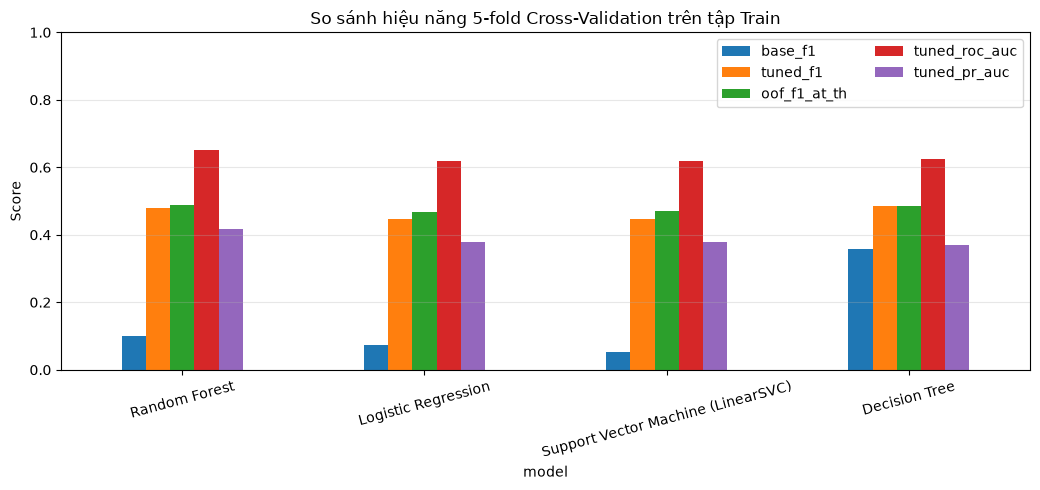

Đã lưu biểu đồ CV: E:\07_Active_Projects\coding\mechine_learning\customer_churn_ml\telecom-churn-ml\results\figures\07_cv_comparison.png


In [2]:
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

plot_df = cv_table.set_index("model")[["base_f1", "tuned_f1", "oof_f1_at_th", "tuned_roc_auc", "tuned_pr_auc"]]
ax = plot_df.plot(kind="bar", figsize=(10.5, 5), rot=15)
ax.set_title("So sánh hiệu năng 5-fold Cross-Validation trên tập Train")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.0)
ax.grid(axis="y", alpha=0.3)
ax.legend(loc="upper right", ncol=2)
plt.tight_layout()
cv_fig_path = FIGURES_DIR / "07_cv_comparison.png"
plt.savefig(cv_fig_path, dpi=150)
plt.show()
print("Đã lưu biểu đồ CV:", cv_fig_path)

## 3. Fit lại trên 100% tập Train & Đánh giá 1 lần duy nhất trên tập Test (10.210 dòng)
Sử dụng đúng `tuned_best_params` và `best_oof_threshold` đã chốt từ tập Train (không tinh chỉnh lại trên Test).

,key,model,fit_predict_sec,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc
0,05_random_forest,Random Forest,4.86,0.45,0.4797,0.3393,0.8504,0.4851,0.6480,0.4146
1,03_logistic_regression,Logistic Regression,2.80,0.45,0.4888,0.3334,0.7743,0.4661,0.6132,0.3725
2,06_svm,Support Vector Machine (LinearSVC),4.60,0.25,0.4853,0.3324,0.7797,0.4661,0.6118,0.3701
3,04_decision_tree,Decision Tree,8.32,0.40,0.4822,0.3366,0.8209,0.4774,0.6164,0.3666


Đã lưu bảng kết quả Test: E:\07_Active_Projects\coding\mechine_learning\customer_churn_ml\telecom-churn-ml\results\metrics\07_test_comparison.csv


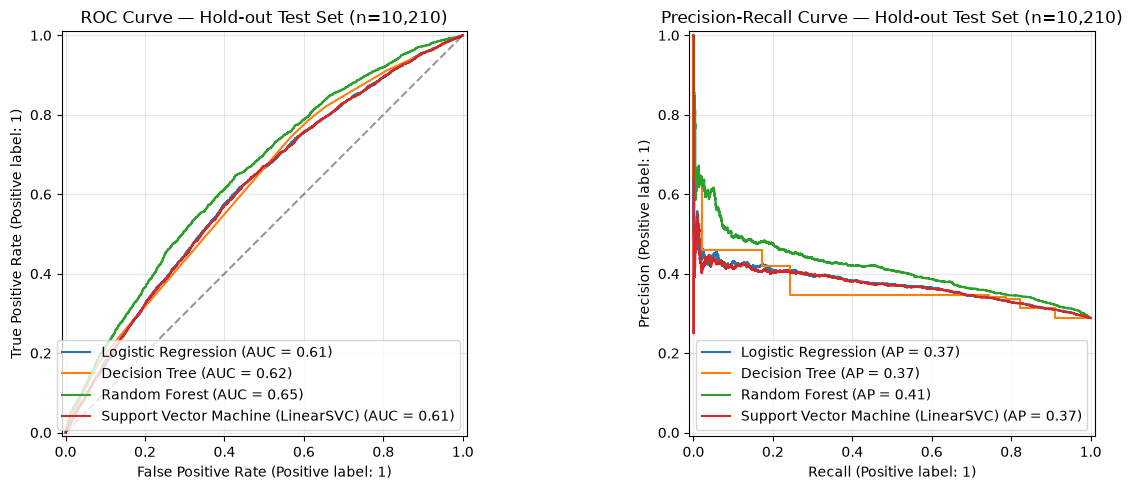

Đã lưu biểu đồ ROC/PR: E:\07_Active_Projects\coding\mechine_learning\customer_churn_ml\telecom-churn-ml\results\figures\07_test_roc_pr.png


In [3]:
X_train, X_test, y_train, y_test, NUM_COLS, CAT_COLS = load_train_test()
preprocessor = build_preprocessor(NUM_COLS, CAT_COLS, min_frequency=50)

MODEL_BUILDERS = {
    "03_logistic_regression": lambda p: LogisticRegression(max_iter=3000, random_state=RANDOM_STATE, **p),
    "04_decision_tree":       lambda p: DecisionTreeClassifier(random_state=RANDOM_STATE, **p),
    "05_random_forest":       lambda p: RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1, **p),
    "06_svm":                 lambda p: LinearSVC(dual="auto", max_iter=5000, random_state=RANDOM_STATE, **p),
}

fitted_pipelines = {}
test_probas = {}
test_rows = []

for key, rep in reports.items():
    if key not in MODEL_BUILDERS:
        continue
    t0 = time.time()
    raw_est = MODEL_BUILDERS[key](rep["tuned_best_params"])
    proba_est = ensure_proba_model(raw_est)

    pipe = make_pipeline(preprocessor, proba_est)
    pipe.fit(X_train, y_train)

    y_prob = pipe.predict_proba(X_test)[:, 1]
    metrics = compute_test_metrics(y_test, y_prob, threshold=rep["best_oof_threshold"])
    elapsed = round(time.time() - t0, 2)

    fitted_pipelines[key] = pipe
    test_probas[key] = y_prob
    test_rows.append({
        "key": key,
        "model": rep["model"],
        "fit_predict_sec": elapsed,
        **metrics,
    })

test_table = pd.DataFrame(test_rows).sort_values("pr_auc", ascending=False).reset_index(drop=True)
display(test_table)

test_csv_path = METRICS_DIR / "07_test_comparison.csv"
test_table.to_csv(test_csv_path, index=False)
print("Đã lưu bảng kết quả Test:", test_csv_path)

# Vẽ chồng đường cong ROC & Precision-Recall trên tập Test
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for key, y_prob in test_probas.items():
    label = reports[key]["model"]
    RocCurveDisplay.from_predictions(y_test, y_prob, name=label, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_test, y_prob, name=label, ax=axes[1])

axes[0].plot([0, 1], [0, 1], "k--", alpha=0.4)
axes[0].set_title("ROC Curve — Hold-out Test Set (n=10,210)")
axes[0].grid(alpha=0.3)
axes[1].set_title("Precision-Recall Curve — Hold-out Test Set (n=10,210)")
axes[1].grid(alpha=0.3)
plt.tight_layout()
roc_pr_path = FIGURES_DIR / "07_test_roc_pr.png"
fig.savefig(roc_pr_path, dpi=150)
plt.show()
print("Đã lưu biểu đồ ROC/PR:", roc_pr_path)

## 4. Chốt mô hình thắng cuộc (theo CV) & Đóng gói `models/churn_pipeline.joblib`
Mô hình thắng cuộc được chọn từ dòng đầu tiên của `cv_table` (ưu tiên `tuned_pr_auc`, đồng hạng xét `oof_f1_at_th`). Toàn bộ `preprocessor` đã fit + `model` được đóng gói thành 1 file `.joblib` duy nhất kèm `model_meta.json`.

Mô hình thắng cuộc (chọn theo CV): Random Forest (05_random_forest)
Ngưỡng phân loại OOF đã chốt     : 0.45
Kết quả trên Hold-out Test       : {'key': '05_random_forest', 'model': 'Random Forest', 'fit_predict_sec': 4.86, 'threshold': 0.45, 'accuracy': 0.4797, 'precision': 0.3393, 'recall': 0.8504, 'f1': 0.4851, 'roc_auc': 0.648, 'pr_auc': 0.4146}


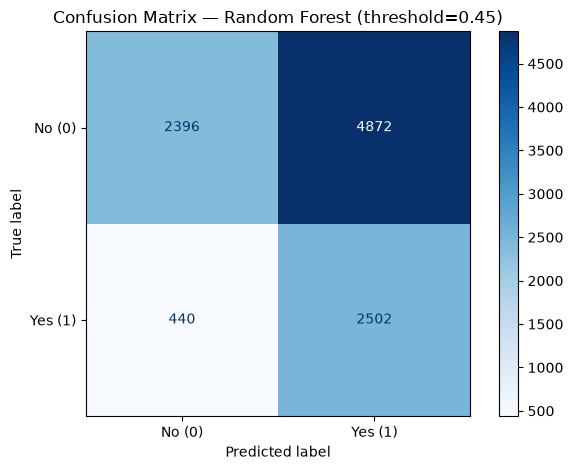

Đã lưu Confusion Matrix: E:\07_Active_Projects\coding\mechine_learning\customer_churn_ml\telecom-churn-ml\results\figures\07_winner_confusion_matrix.png
Đã đóng gói thành công: E:\07_Active_Projects\coding\mechine_learning\customer_churn_ml\telecom-churn-ml\models\churn_pipeline.joblib (731.7 KB)
Đã lưu metadata       : E:\07_Active_Projects\coding\mechine_learning\customer_churn_ml\telecom-churn-ml\models\model_meta.json


In [4]:
winner_key = cv_table.iloc[0]["key"]
winner_name = reports[winner_key]["model"]
winner_pipe = fitted_pipelines[winner_key]
winner_th = reports[winner_key]["best_oof_threshold"]
winner_test_metrics = test_table.loc[test_table["key"] == winner_key].iloc[0].to_dict()

print(f"Mô hình thắng cuộc (chọn theo CV): {winner_name} ({winner_key})")
print(f"Ngưỡng phân loại OOF đã chốt     : {winner_th}")
print("Kết quả trên Hold-out Test       :", winner_test_metrics)

# Vẽ Confusion Matrix của mô hình thắng cuộc trên Test
y_win_pred = (test_probas[winner_key] >= winner_th).astype(int)
disp = ConfusionMatrixDisplay.from_predictions(
    y_test, y_win_pred, display_labels=["No (0)", "Yes (1)"], cmap="Blues"
)
disp.ax_.set_title(f"Confusion Matrix — {winner_name} (threshold={winner_th})")
plt.tight_layout()
cm_path = FIGURES_DIR / "07_winner_confusion_matrix.png"
disp.figure_.savefig(cm_path, dpi=150)
plt.show()
print("Đã lưu Confusion Matrix:", cm_path)

# Xuất artifact triển khai
MODELS_DIR.mkdir(parents=True, exist_ok=True)
model_path = MODELS_DIR / "churn_pipeline.joblib"
meta_path = MODELS_DIR / "model_meta.json"

joblib.dump(winner_pipe, model_path, compress=3)
meta = {
    "winner_key": winner_key,
    "model_name": winner_name,
    "tuned_best_params": reports[winner_key]["tuned_best_params"],
    "num_cols": NUM_COLS,
    "cat_cols": CAT_COLS,
    "threshold": winner_th,
    "cv_metrics": reports[winner_key]["tuned_cv"],
    "test_metrics": winner_test_metrics,
}
meta_path.write_text(json.dumps(meta, indent=2, default=str), encoding="utf-8")

print(f"Đã đóng gói thành công: {model_path} ({model_path.stat().st_size / 1024:.1f} KB)")
print(f"Đã lưu metadata       : {meta_path}")

## 5. Kiểm thử triển khai trên 20.000 khách hàng chưa nhãn (`Telecom - Prediction Data.csv`)
Mô phỏng đúng luồng thực tế (Web/API): nạp lại `churn_pipeline.joblib` + `model_meta.json`, chuẩn hóa dữ liệu thô qua `prepare_raw_input()` và xuất file kết quả `results/predictions/telecom_predictions.csv`.

Đã xuất dự đoán cho 20,000 khách hàng tại: E:\07_Active_Projects\coding\mechine_learning\customer_churn_ml\telecom-churn-ml\results\predictions\telecom_predictions.csv


,CustomerID,churn_probability,prediction
0,3000006,0.4011,No
1,3000018,0.4763,Yes
2,3000034,0.4683,Yes
3,3000070,0.4377,No
4,3000074,0.4630,Yes
5,3000086,0.4384,No
6,3000098,0.5131,Yes
7,3000110,0.4827,Yes
8,3000246,0.5460,Yes
9,3000254,0.4331,No



Phân bố nhãn dự đoán trên Telecom - Prediction Data (%):


,percent (%)
prediction,
Yes,72.36
No,27.64


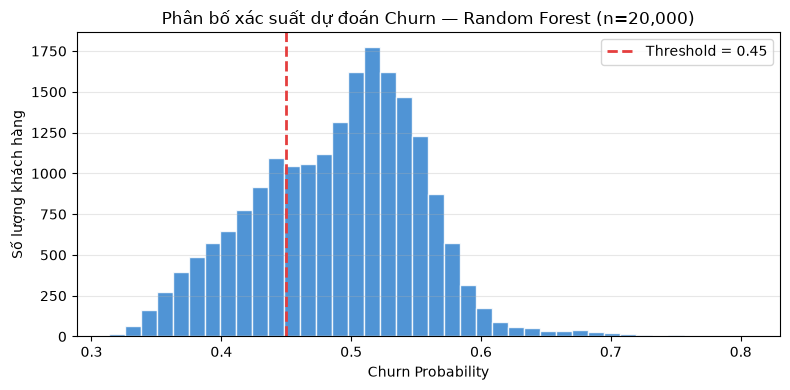

Đã lưu biểu đồ phân bố xác suất: E:\07_Active_Projects\coding\mechine_learning\customer_churn_ml\telecom-churn-ml\results\figures\07_prediction_prob_dist.png


In [5]:
loaded_pipe = joblib.load(MODELS_DIR / "churn_pipeline.joblib")
loaded_meta = json.loads((MODELS_DIR / "model_meta.json").read_text(encoding="utf-8"))

if not PRED_DATA_PATH.exists():
    raise FileNotFoundError(f"Không tìm thấy tập dự đoán: {PRED_DATA_PATH}")

raw_pred_df = pd.read_csv(PRED_DATA_PATH)
X_new = prepare_raw_input(raw_pred_df, loaded_meta["num_cols"], loaded_meta["cat_cols"])

probs = loaded_pipe.predict_proba(X_new)[:, 1]
preds = np.where(probs >= loaded_meta["threshold"], "Yes", "No")

out_df = pd.DataFrame({
    ID_COL: raw_pred_df[ID_COL],
    "churn_probability": np.round(probs, 4),
    "prediction": preds,
})

PREDICTIONS_DIR.mkdir(parents=True, exist_ok=True)
out_csv = PREDICTIONS_DIR / "telecom_predictions.csv"
out_df.to_csv(out_csv, index=False)

print(f"Đã xuất dự đoán cho {len(out_df):,} khách hàng tại: {out_csv}")
display(out_df.head(10))

print("\nPhân bố nhãn dự đoán trên Telecom - Prediction Data (%):")
display(out_df["prediction"].value_counts(normalize=True).mul(100).round(2).to_frame("percent (%)"))

# Vẽ phân bố xác suất dự đoán
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(probs, bins=40, color="#3182ce", edgecolor="white", alpha=0.85)
ax.axvline(loaded_meta["threshold"], color="#e53e3e", linestyle="--", linewidth=2,
           label=f"Threshold = {loaded_meta['threshold']}")
ax.set_title(f"Phân bố xác suất dự đoán Churn — {loaded_meta['model_name']} (n={len(out_df):,})")
ax.set_xlabel("Churn Probability")
ax.set_ylabel("Số lượng khách hàng")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
pred_fig_path = FIGURES_DIR / "07_prediction_prob_dist.png"
plt.savefig(pred_fig_path, dpi=150)
plt.show()
print("Đã lưu biểu đồ phân bố xác suất:", pred_fig_path)

## 6. Ghi chú tổng hợp cho Báo cáo & Chương Triển khai
- **So sánh công bằng:** Trình bày bảng `cv_table` (Train CV) và `test_table` (Hold-out Test), giải thích lý do ưu tiên `PR-AUC` và `F1` thay vì `Accuracy` trong bài toán Churn mất cân bằng (`~28.82%`).
- **Đánh giá tổng quát hóa:** Đối chiếu điểm CV và điểm Test của mô hình thắng cuộc để chứng minh không bị overfitting hay data leakage.
- **Khả năng ứng dụng thực tế:** Trình bày cấu trúc đóng gói `churn_pipeline.joblib` + `model_meta.json` cùng kết quả suy luận trên 20.000 khách hàng mới (`telecom_predictions.csv`).